In [23]:
import os
import random
import requests
from typing import Annotated, override
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver

load_dotenv(override=True)

True

## The State, and a word about reducers

The state is the object that flows through the graph. We describe it with a TypedDict. Each field updates on its own, and by default a new value simply replaces the old one.

Sometimes we want updates to accumulate instead. A reducer is a small function that says how to combine the old value with the new one. We attach it with Annotated. LangGraph ships the reducer we want for chat, add_messages, which appends new messages to the running list rather than overwriting it.

In [4]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

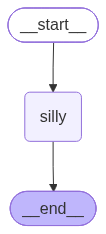

In [ ]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

#TypedDict says what the state looks like. 
# At runtime it’s just a dict, {"messages": [...]}. The type is only for LangGraph and your editor.

def silly_node(state: State) -> dict:
    sentence = f"{random.choice(nouns)} are {random.choice(adjectives)}"
    return {"messages": [{"role": "assistant", "content": sentence}]}

builder = StateGraph(State)
builder.add_node("silly", silly_node)
builder.add_edge(START, "silly")
builder.add_edge("silly", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
result = graph.invoke({"messages": [{"role": "user", "content": "say something"}]})
print(result["messages"][-1].content)
print(result["messages"])

Toasters are haunted
[HumanMessage(content='say something', additional_kwargs={}, response_metadata={}, id='72dc41c8-b5f1-43ad-91e9-bbed63c91bc8'), AIMessage(content='Toasters are haunted', additional_kwargs={}, response_metadata={}, id='4ee3abfa-a58f-4a33-978e-b2aefacd2a52', tool_calls=[], invalid_tool_calls=[])]


# Adding a LLM to the Graph

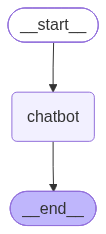

In [12]:
llm = ChatOpenAI(model="gpt-4o-mini")

def chatbot_node(state: State) -> dict:
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
result = graph.invoke({"messages": [{"role": "user", "content": "What is a directed graph, in one sentence?"}]})
print(result["messages"][-1].content)

A directed graph, or digraph, is a set of vertices connected by edges that have a specific direction, indicating a one-way relationship between the vertices.


# Adding tools: a node, a condition, and a loop

In [15]:
search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

@tool
def send_push_notification(text: str) -> str:
    """Send a short push notification to the user's phone."""
   
    return "Notification sent"

tools = [search, send_push_notification]
llm_with_tools = llm.bind_tools(tools)

# The Sequence

Node	What happens there

Chatbot || 	Choice. The LLM reads the conversation and the tool descriptions and decides whether to call a tool, which one, and with what arguments. It only writes a request, a tool_calls entry in its AIMessage. No tool runs here.

(edge) tools_condition	|| Routing. It checks whether that last message has tool_calls. If it does, it goes to tools; if not, the graph ends.

tools (ToolNode)	|| Execution. It reads the request, calls your Python function (get_weather(city="Lisbon")), and adds the result as a ToolMessage.

back to chatbot	 || The LLM reads the result and either answers or requests another tool.

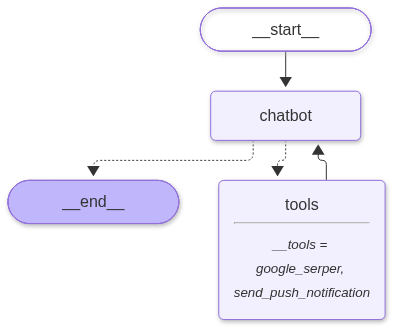

In [ ]:
# The chatbot initial node reads the conversation and the tool description and decides whether to call a tool or not.
# It only writes a request a "tool call " in it's AI message.
# (edge) tools_condition The Routing. It checks whether that last message has tool_calls. If it does, it goes to tools; if not, the graph ends.
#

def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [19]:
result = graph.invoke({"messages": [{"role": "user", "content": "Use your search tool to tell me the ingredients in banoffee pie and send me a push notification."}]})
print(result["messages"][-1].content)
for m in result["messages"]:
    m.pretty_print()

The ingredients for banoffee pie include:

- 150g/5½oz digestive biscuits (about 10)
- 75g/2¾oz butter (melted)
- 397g can of caramel (or dulce de leche)
- 3 small bananas (sliced)
- 300ml double cream (whipped)
- 1 tablespoon icing sugar

Banoffee pie is a delightful English dessert that combines bananas and toffee! If you need any more information, feel free to ask.
================================ Human Message =================================

Use your search tool to tell me the ingredients in banoffee pie and send me a push notification.
================================== Ai Message ==================================
Tool Calls:
  google_serper (call_cgrLFxawwrfV7ngjQw5hmxho)
 Call ID: call_cgrLFxawwrfV7ngjQw5hmxho
  Args:
    query: ingredients in banoffee pie
  send_push_notification (call_Jyu9qQMk8dNFkqqWK1A8jTfC)
 Call ID: call_Jyu9qQMk8dNFkqqWK1A8jTfC
  Args:
    text: Searching for ingredients in banoffee pie...
================================= Tool Message ===============

# A second LLM node: the translator

Nodes do not have to be part of the tool loop. Any function can be a node, including one that makes its own LLM call. To prove it, we will add a translator that writes a Spanish version of the final answer into the state.

Two things are new here. First, the state gains a second field, spanish. It has no reducer, so each run simply overwrites it, which is just what we want. Second, until now tools_condition has sent the finished conversation straight to END. By passing a mapping as the third argument, we send that branch through the translator instead, and the translator ends the run.

Look closely at the rendered graph this time. There are two nodes that call an LLM: the chatbot, which has tools and sits in a loop, and the translator, which makes one plain call on the way out. And since the translator runs after the chatbot has finished, it gets a super-step of its own.

## Langgraph execution

Step 2: LangGraph copies that dict into the state

You don’t see this code; it runs inside graph.invoke(...) after every node. Simplified, it does:

Python
# inside LangGraph, after a node finishes:
update = translator_node(state)                   # {"spanish": "Las coles son brillantes"}

for key, value in update.items():                 # key = "spanish"
    if key not in State's keys:                   # ("messages", "spanish") from your class
        continue                                  # unknown key: ignored (the typo case)
    if key has a reducer:                         # messages → add_messages
        state[key] = reducer(state[key], value)   #   append
    else:                                         # spanish → no reducer
        state[key] = value                        #   overwrite

That state[key] = value line is where spanish actually gets its value. LangGraph runs it because:

your dict has the key "spanish";
your State class declares a key called spanish, so LangGraph accepts it;
spanish has no reducer, so the value is simply stored.

### So a node never changes the state directly. It returns a dict of proposed changes, and LangGraph writes them into the state, matching by key name against your State class. The name spanish connects the two only because you wrote the same word in both places.

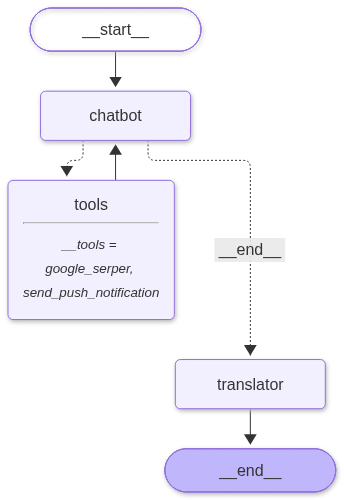

In [20]:
#class State(TypedDict) is a description, not an object
#A normal class describes objects with attributes. A TypedDict class only describes what a dictionary should contain:

#This says: “a State is a dict with a key "messages" whose value is a list, and a key "spanish" whose value is a string.”


class State(TypedDict):
    messages: Annotated[list, add_messages]
    spanish: str

def translator_node(state: State) -> dict:
    last = state["messages"][-1].content
    prompt = f"Translate this into Spanish, replying with the translation only:\n\n{last}"
    return {"spanish": llm.invoke(prompt).content}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END:"translator"})
builder.add_edge("tools", "chatbot")
builder.add_edge("translator", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
result = graph.invoke({"messages": [{"role": "user", "content": "In one sentence, what is special about a banana?"}]})
print(result["messages"][-1].content)
print(result["spanish"])

Bananas are unique in that they are berries botanically, and they contain a natural compound called tryptophan, which can help boost serotonin levels and improve mood.
Las bananas son únicas en que son bayas botánicamente, y contienen un compuesto natural llamado triptófano, que puede ayudar a aumentar los niveles de serotonina y mejorar el estado de ánimo.


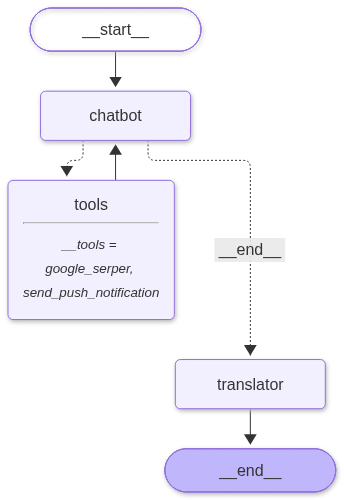

Your name is Ed.
Tu nombre es Ed.


In [25]:
memory = MemorySaver()

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition, {"tools": "tools", END: "translator"})
builder.add_edge("translator", END)
builder.add_edge("tools", "chatbot")
graph = builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))

config = {"configurable": {"thread_id": "conversation-1"}}
graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is Ed."}]}, config)
second = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
print(second["messages"][-1].content)
print(second["spanish"])

# SQLite

In [26]:
with SqliteSaver.from_conn_string("memory.db") as sql_memory:
    durable_graph = builder.compile(checkpointer=sql_memory)
    sql_config = {"configurable": {"thread_id": "conversation-2"}}
    durable_graph.invoke({"messages": [{"role": "user", "content": "Remember that my favorite color is orange."}]}, sql_config)
    reply = durable_graph.invoke({"messages": [{"role": "user", "content": "What is my favorite color?"}]}, sql_config)
    print(reply["messages"][-1].content)
    print(reply["spanish"])

Your favorite color is orange.
Tu color favorito es el naranja.


In [28]:
snapshot = graph.get_state(config)
messages = snapshot.values["messages"]
print("Messages stored so far:", len(messages))

for message in messages:
    print(message.content)

history = list(graph.get_state_history(config))
print("Number of saved checkpoints:", len(history))




for h in reversed(history):            # history is newest first; reversed reads as a story
      m = h.metadata
      queued = ", ".join(t.name for t in h.tasks) or "(run complete)"
      print(f"step {m['step']:>2}  {m['source']:<5}  messages={len(h.values.get('messages', []))}  about to run: {queued}")

Messages stored so far: 4
Hi, my name is Ed.
Hi Ed! How can I assist you today?
What is my name?
Your name is Ed.
Number of saved checkpoints: 8
step -1  input  messages=0  about to run: __start__
step  0  loop   messages=1  about to run: chatbot
step  1  loop   messages=2  about to run: translator
step  2  loop   messages=2  about to run: (run complete)
step  3  input  messages=2  about to run: __start__
step  4  loop   messages=3  about to run: chatbot
step  5  loop   messages=4  about to run: translator
step  6  loop   messages=4  about to run: (run complete)


In [29]:
# Time travel: take a checkpoint from earlier and resume the graph from that exact moment
earlier = history[len(history) // 2]
print("A checkpoint from earlier held", len(earlier.values["messages"]), "messages")

replay_config = {"configurable": {"thread_id": "conversation-1",
                                  "checkpoint_id": earlier.config["configurable"]["checkpoint_id"]}}
resumed = graph.invoke(None, replay_config)
print("Resumed from the past; the graph now holds", len(resumed["messages"]), "messages")

again = graph.invoke({"messages": [{"role": "user", "content": "What do you know about me?"}]}, replay_config)
print(again["messages"][-1].content)
print(again["spanish"])

A checkpoint from earlier held 2 messages
Resumed from the past; the graph now holds 2 messages
I don't have any specific information about you, Ed, other than your name. I am designed to respect user privacy and confidentiality. If you have any questions or need assistance, feel free to ask!
No tengo ninguna información específica sobre ti, Ed, aparte de tu nombre. Estoy diseñado para respetar la privacidad y la confidencialidad de los usuarios. Si tienes alguna pregunta o necesitas ayuda, ¡no dudes en preguntar!


# UI Gradio

In [30]:
def chat(user_input: str, history):
    config = {"configurable": {"thread_id": "gradio-session4"}}
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config)
    return f"{result['messages'][-1].content}\n\n*{result['spanish']}*"

gr.ChatInterface(chat).launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
